In [8]:
from MultiAgent_DQ import *
import numpy as np
import pandas as pd  
import itertools
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import pandas as pd
import sys
sys.path.append('../')
import tqdm
from utils import *


In [9]:
# reading results from simulations

In [10]:
#df = pd.read_csv("../results/results_from_vectorized_script_raw.csv")
df_fixed = pd.read_csv("../results/results_vect_paramsfixed_time.csv")

In [11]:
#excluding lambda > 0.8
df_fixed = df_fixed[df_fixed['lambda']<=0.8]

In [12]:
def round_columns(df, columns, decimals):
    for column in columns:
        df[column] = df[column].round(decimals)
    return df

def round_to_quarters(df, columns, decimals):
    for column in columns:
        df[column] = (df[column]/ 0.25).round(decimals)* 0.25
    return df

# Columns to round
columns_to_round = ['delta', 'e', 'lambda', 'alpha']

# Apply the function to df
# Apply the function to df_fixed
df_fixed = round_columns(df_fixed, columns_to_round, 2)
df_fixed['M'] = df_fixed['M'].round(0)

In [13]:
columns = ['delta', 'e', 'lambda', 'alpha']

# Generate all pairwise combinations of the columns
pair_combinations = list(itertools.combinations(columns, 2))

# Display the pair combinations
print(pair_combinations)

[('delta', 'e'), ('delta', 'lambda'), ('delta', 'alpha'), ('e', 'lambda'), ('e', 'alpha'), ('lambda', 'alpha')]


In [14]:
fixed_pairs = [(0.09, 0.09), (0.09, 0.5), (1., 0.09), (1., 0.5)]
heatmap_fixed_pairs(df_fixed, 'delta', 'e', 'P_AD', fixed_pairs)


NameError: name 'heatmap_fixed_pairs' is not defined

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize
import matplotlib.cm as cm

def heatmap_3d_voxels(df, xaxis, yaxis, zaxis, value='P_AD'):
    # Compute mean value for each (x, y, z) triple
    grouped = df.groupby([xaxis, yaxis, zaxis])[value].mean().reset_index()

    # Map categories to integer indices
    x_labels = sorted(df[xaxis].unique())
    y_labels = sorted(df[yaxis].unique())
    z_labels = sorted(df[zaxis].unique())

    x_map = {k: i for i, k in enumerate(x_labels)}
    y_map = {k: i for i, k in enumerate(y_labels)}
    z_map = {k: i for i, k in enumerate(z_labels)}

    # Prepare empty 3D grid
    shape = (len(x_labels), len(y_labels), len(z_labels))
    grid = np.full(shape, np.nan)

    for _, row in grouped.iterrows():
        xi = x_map[row[xaxis]]
        yi = y_map[row[yaxis]]
        zi = z_map[row[zaxis]]
        grid[xi, yi, zi] = row[value]

    # Create voxel mask
    mask = ~np.isnan(grid)

    # Normalize values for colormap
    norm = Normalize(vmin=np.nanmin(grid), vmax=np.nanmax(grid))
    cmap = cm.get_cmap('Oranges')

    # Build RGBA colors based on value
    colors = np.zeros(grid.shape + (4,))
    for idx, val in np.ndenumerate(grid):
        if not np.isnan(val):
            colors[idx] = cmap(norm(val))

    # Plot voxels
    fig = plt.figure(figsize=(20, 20))
    ax = fig.add_subplot(111, projection='3d')

    ax.voxels(mask, facecolors=colors, edgecolor='k')

    ax.set_xticks(np.arange(len(x_labels)) + 0.5)
    ax.set_xticklabels(x_labels, rotation=45, ha='right')
    ax.set_yticks(np.arange(len(y_labels)) + 0.5)
    ax.set_yticklabels(y_labels, rotation=45, ha='right')
    ax.set_zticks(np.arange(len(z_labels)) + 0.5)
    ax.set_zticklabels(z_labels)

    ax.set_xlabel(xaxis)
    ax.set_ylabel(yaxis)
    ax.set_zlabel(zaxis)
    ax.set_title(f'3D Voxel Heatmap of {value} by {xaxis}, {yaxis}, and {zaxis}')

    # Colorbar
    mappable = cm.ScalarMappable(norm=norm, cmap=cmap)
    cbar = fig.colorbar(mappable, ax=ax, shrink=0.6, pad=0.1)
    cbar.set_label(f'Mean {value}')

    plt.tight_layout()
    plt.show()


/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_75893/719322334.py:35: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('Oranges')
/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_75893/719322334.py:66: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


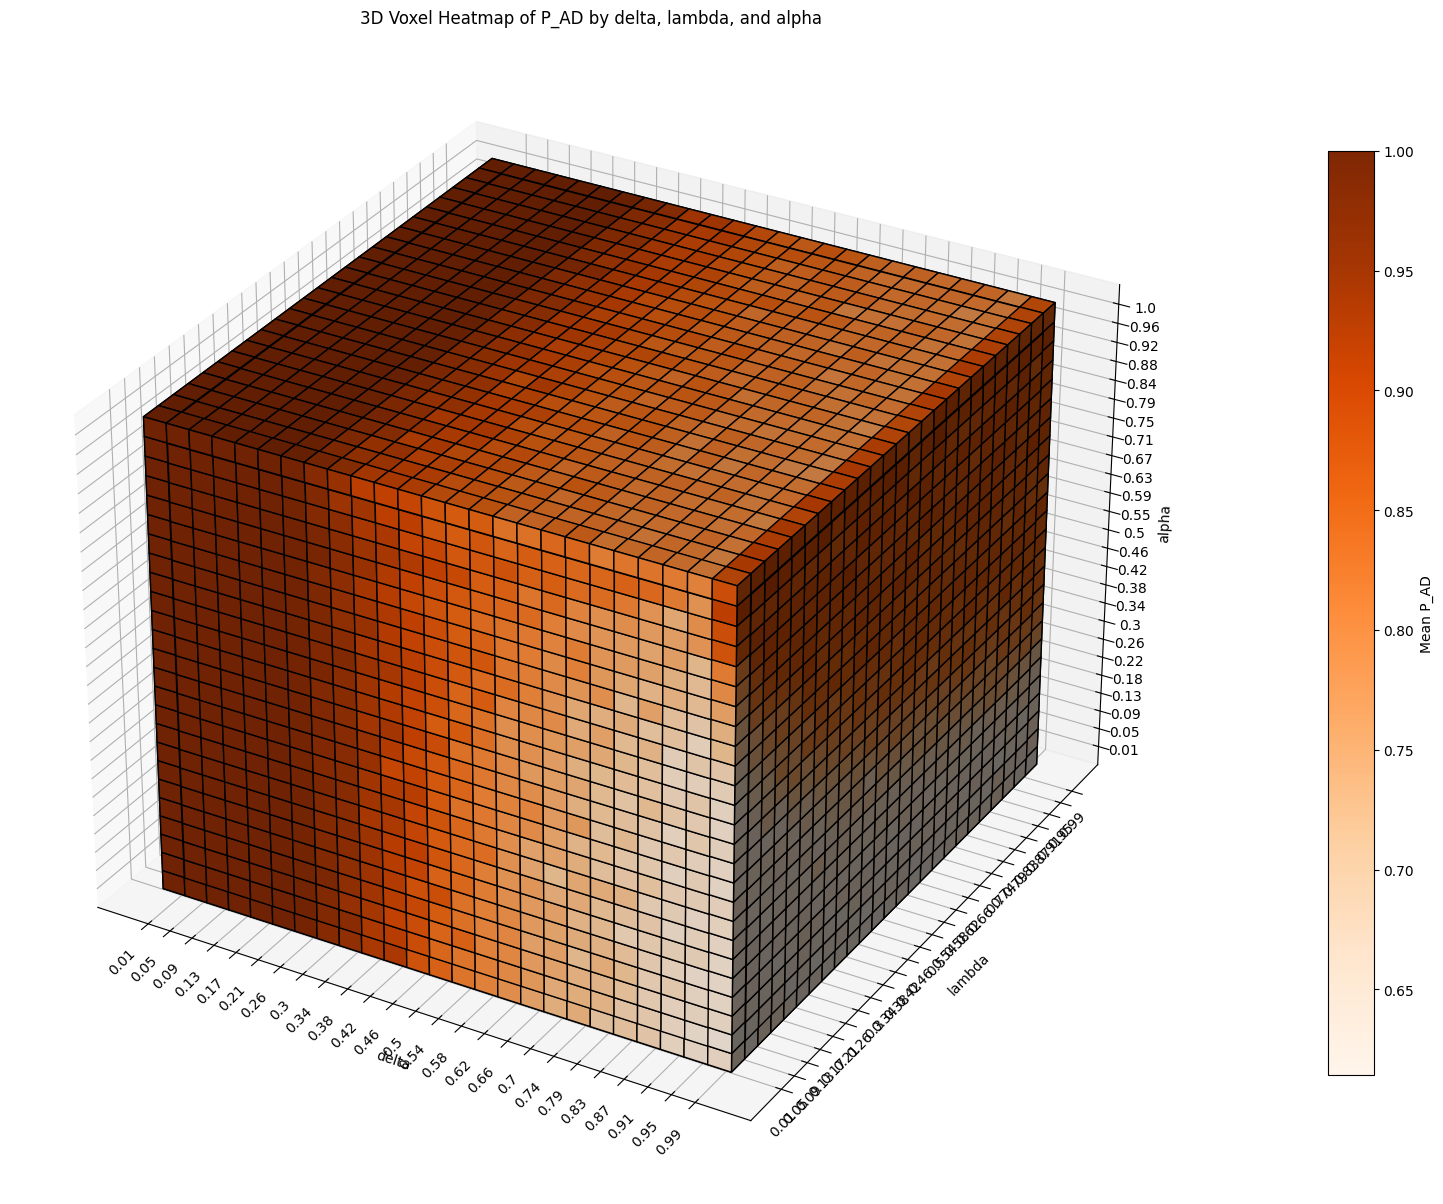

In [14]:
heatmap_3d_voxels(df, 'delta', 'lambda', 'alpha', value='P_AD')

In [15]:
import plotly.graph_objects as go
import pandas as pd
import numpy as np
import plotly.graph_objects as go

def interactive_3d_voxel(df, xaxis, yaxis, zaxis, value='P_AD', html=False):
    greek_labels = {
    "alpha": "α",
    "beta": "β",
    "delta": "δ",
    "epsilon": "ε",
    "e": "ε",
    "lambda": "λ",
    "mu": "μ",
    "M": "M",  # Latin letter
    "P_GT": "P_GT",  # Optional: use subscript formatting if needed
    "P_AD": "P_AD",
}


    grouped = df.groupby([xaxis, yaxis, zaxis])[value].mean().reset_index()

    # Map categorical to numeric
    x_labels = sorted(df[xaxis].unique())
    y_labels = sorted(df[yaxis].unique())
    z_labels = sorted(df[zaxis].unique())

    x_map = {k: i for i, k in enumerate(x_labels)}
    y_map = {k: i for i, k in enumerate(y_labels)}
    z_map = {k: i for i, k in enumerate(z_labels)}

    # Map to numeric positions
    grouped[str(xaxis)] = grouped[xaxis].map(x_map)
    grouped[str(yaxis)] = grouped[yaxis].map(y_map)
    grouped[str(zaxis)] = grouped[zaxis].map(z_map)

    fig = go.Figure(data=go.Scatter3d(
        x=grouped[str(xaxis)],
        y=grouped[str(yaxis)],
        z=grouped[str(zaxis)],
        mode='markers',
        marker=dict(
            size=20,
            color=grouped[value],
            colorscale='Inferno',
            colorbar=dict(title=greek_labels.get(value, value)),
            opacity=0.8,
        ),
        text=[f'{value}: {v:.2f}' for v in grouped[value]]
    ))

    # ✅ Reduce tick labels (every 2nd for clarity)
    x_ticks_sparse = x_labels[::2]
    y_ticks_sparse = y_labels[::2]
    z_ticks_sparse = z_labels[::2]

    fig.update_layout(
        width=1000,
        height=800,
        scene=dict(
            xaxis=dict(
                title=greek_labels.get(xaxis, xaxis),
                tickvals=[x_map[v] for v in x_ticks_sparse],
                ticktext=x_ticks_sparse
            ),
            yaxis=dict(
                title=greek_labels.get(yaxis, yaxis),
                tickvals=[y_map[v] for v in y_ticks_sparse],
                ticktext=y_ticks_sparse
            ),
            zaxis=dict(
                title=greek_labels.get(zaxis, zaxis),
                tickvals=[z_map[v] for v in z_ticks_sparse],
                ticktext=z_ticks_sparse
            ),
        ),
        title=f"Interactive 3D Heatmap of {greek_labels.get(value, value)}<br>"
              f"vs {greek_labels.get(xaxis, xaxis)}, {greek_labels.get(yaxis, yaxis)}, {greek_labels.get(zaxis, zaxis)}",
        margin=dict(l=0, r=0, b=0, t=100)
    )

    if html:
        fig.write_html("3dinteractivea.html", full_html=True, include_plotlyjs='cdn')
    else: 
        fig.show()


In [16]:
interactive_3d_voxel(df, 'delta', 'lambda', 'alpha', value='P_AD', html= True)

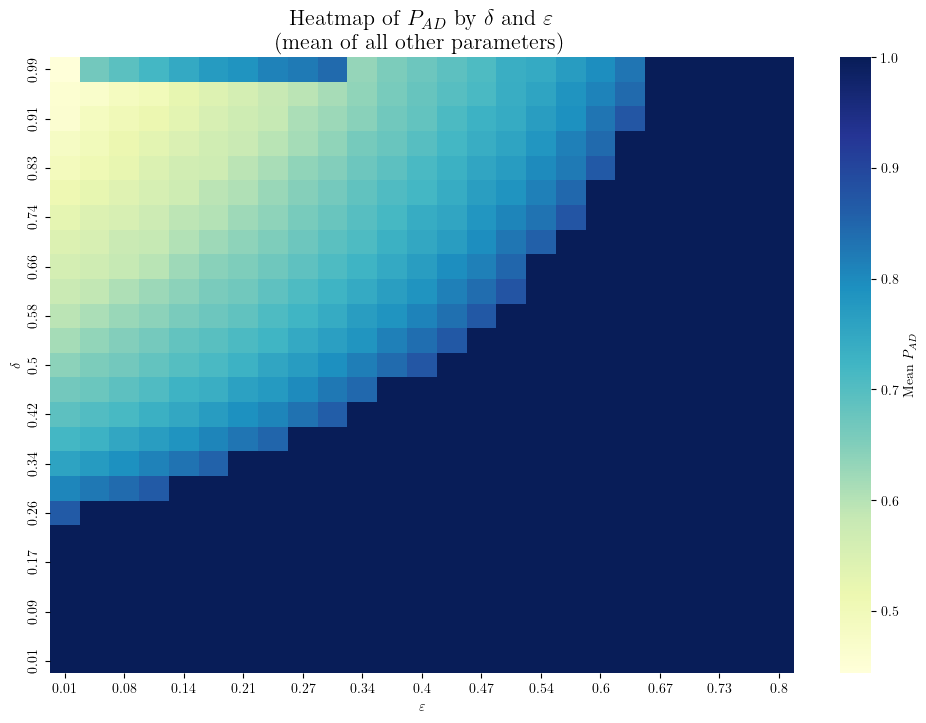

In [15]:
heatmap_mean(df, 'delta', 'e', 'P_AD')
#heatmap_mean(df, 'delta', 'lambda','P_AD')
#heatmap_mean(df, 'delta', 'alpha', 'P_AD')
#heatmap_mean(df, 'e', 'lambda', 'P_AD')
#heatmap_mean(df, 'e', 'alpha', 'P_AD')
#heatmap_mean(df, 'lambda', 'alpha', 'P_AD')

In [16]:
#TODO: as alpha goes to 0, the effect of lambda in equilibrium decreases - flattening?
m = 5000

In [18]:

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.cm as cm

import seaborn as sns
import matplotlib as mpl

# Use LaTeX for text rendering
mpl.rcParams['text.usetex'] = True
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'
def plot_multiple_panels(df, param_sets, x_var, varying_var, y_var, m, use_same_scale=True):
    """
    Plots multiple subplots with a single shared legend.
    """

    # Mapping of variable names to Greek labels
    greek_labels = {
        "alpha": r"$\alpha$",
        "beta": r"$\beta$",
        "delta": r"$\delta$",
        "lambda": r"$\lambda$",
        "mu": r"$\mu$",
        "M": r"$M$",
        "P_GT": r"$P_{GT}$",
        "P_AD": r"$P_{AD}$",
    }

    if y_var not in df.columns:
        raise ValueError(f"The specified y-axis variable '{y_var}' is not in the dataframe.")

    y_limits = (-0.1, 0.7) if use_same_scale else None
    wspace, hspace = (0.02, 0.15) if use_same_scale else (0.2, 0.2)

    fig, axes = plt.subplots(3, 3, figsize=(12, 8), 
                             gridspec_kw={'wspace': wspace, 'hspace': hspace}, 
                             constrained_layout=False)
    axes = axes.flatten()
    
    handles, labels = None, None

    for i, fixed_vars in enumerate(param_sets):
        fixed_vars['M'] = m
        handles, labels = plot_analysis_multiple_lines_sub(
            df, fixed_vars, x_var, varying_var, y_var, axes[i], y_limits
        )
        # Set axis labels per subplot
        # Only show x-label for bottom row
        if i in [6, 7, 8]:
            axes[i].set_xlabel(greek_labels.get(x_var, x_var))
        else:
            axes[i].set_xlabel("")
            axes[i].set_xticklabels([])

        axes[i].set_ylabel(greek_labels.get(y_var, y_var))

    # Add a single legend outside the plot
    if handles and labels:
        fig.legend(handles, labels, title=greek_labels.get(varying_var, varying_var), 
                   loc='upper right', bbox_to_anchor=(1.1, 1))

    # Hide redundant labels for shared scales
    if use_same_scale:
        for ax in axes:
            ax.label_outer()

    plt.show()

def plot_analysis_multiple_lines_sub(df, fixed_vars, x_var, varying_var, y_var, ax, y_limits=None):
    """
    Plots multiple lines in a single subplot without adding a legend.
    """

    greek_labels = {
        "alpha": r"$\alpha$",
        "beta": r"$\beta$",
        "delta": r"$\delta$",
        "epsilon": r"$\varepsilon$",
        "e": r"$\varepsilon$",

        "lambda": r"$\lambda$",
        "mu": r"$\mu$",
        "M": r"$M$",
        "P_GT": r"$P_{GT}$",
        "P_AD": r"$P_{AD}$",
    }

    if y_var not in df.columns:
        raise ValueError(f"The dataframe must contain the column '{y_var}' for plotting.")

    filtered_df = df.copy()
    for var, value in fixed_vars.items():
        filtered_df = filtered_df[filtered_df[var] == value]

    if filtered_df.empty:
        return None, None

    unique_values = sorted(filtered_df[varying_var].unique())    
    norm = plt.Normalize(min(unique_values), max(unique_values))
    cmap = cm.get_cmap('viridis')

    handles, labels = [], []

    for value in unique_values:
        subset = filtered_df[filtered_df[varying_var] == value]
        if not subset.empty:
            label = rf"{greek_labels.get(varying_var, varying_var)} = {value:.3f}"
            line, = ax.plot(
                subset[x_var], subset[y_var], marker='o',
                label=label, color=cmap(norm(value))
            )
            handles.append(line)
            labels.append(label)

    # Format subplot title with Greek letters
    title_parts = [
        rf"{greek_labels.get(k, k)}={v}"
        for k, v in fixed_vars.items() if k != 'M'
    ]
    ax.set_title(r"Fixed: " + ", ".join(title_parts))

    ax.grid()

    if y_limits:
        ax.set_ylim(y_limits)

    return handles, labels


/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_75893/3027414929.py:100: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.

/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_75893/3027414929.py:100: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.

/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_75893/3027414929.py:100: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.

/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_75893/3027414929.

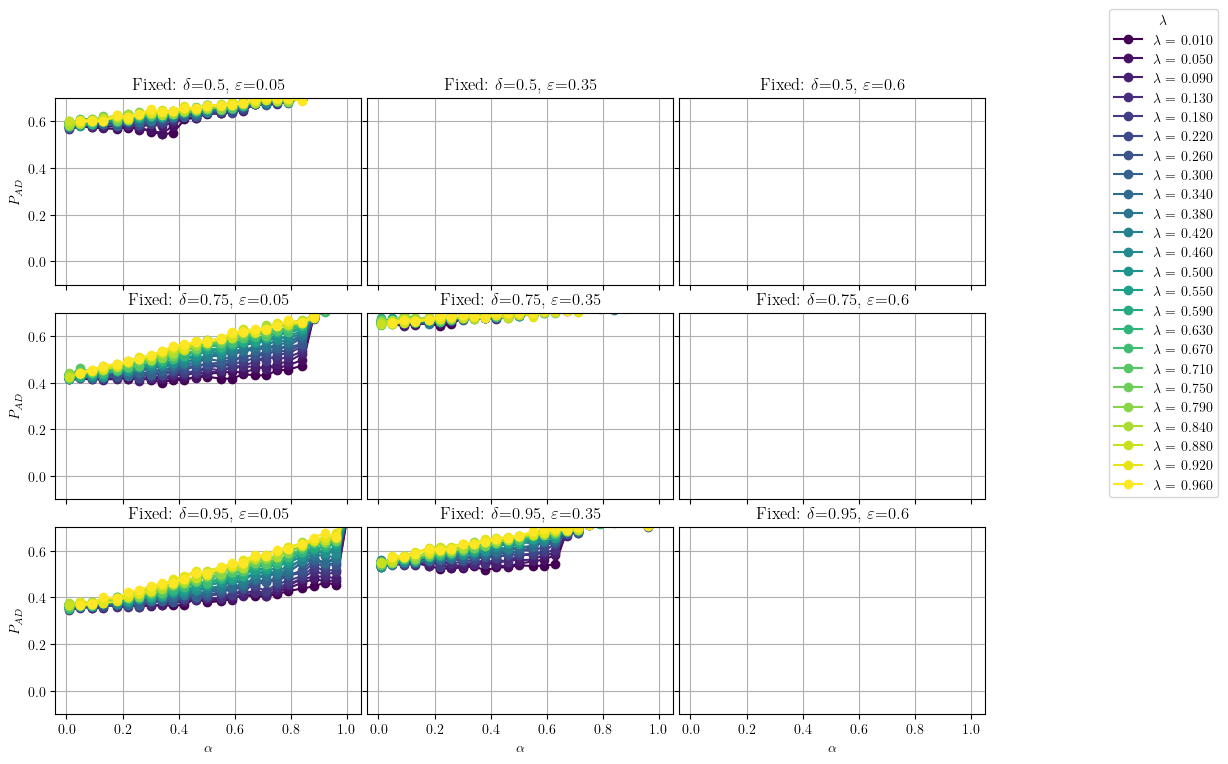

/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_75893/3027414929.py:100: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.

/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_75893/3027414929.py:100: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.

/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_75893/3027414929.py:100: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.

/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_75893/3027414929.

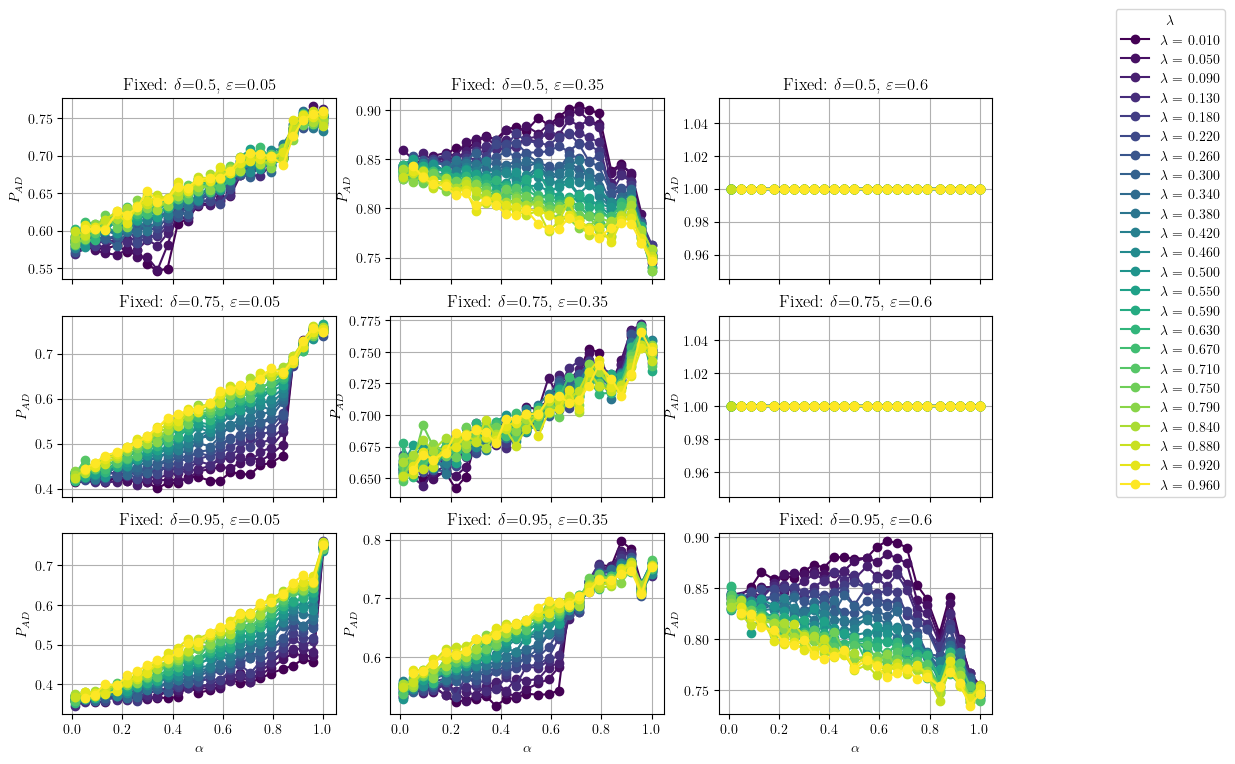

/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_75893/3027414929.py:100: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.

/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_75893/3027414929.py:100: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.

/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_75893/3027414929.py:100: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.

/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_75893/3027414929.

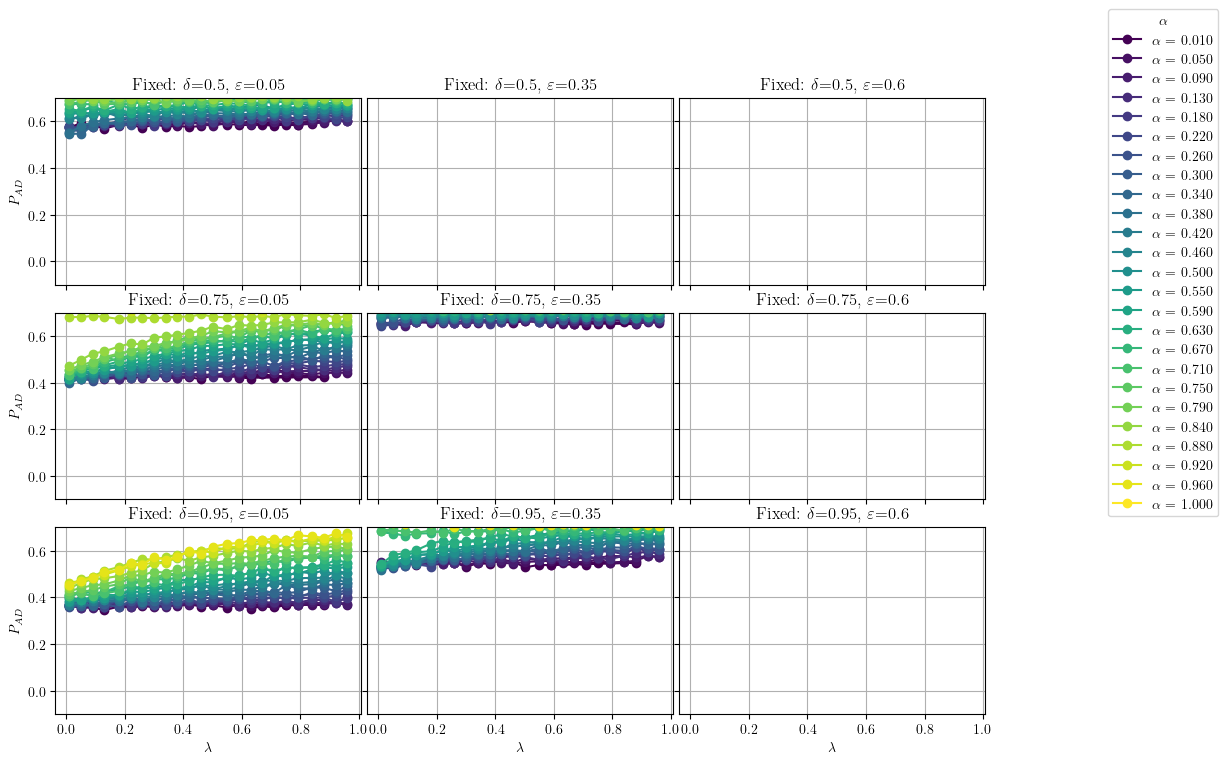

/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_75893/3027414929.py:100: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.

/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_75893/3027414929.py:100: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.

/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_75893/3027414929.py:100: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.

/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_75893/3027414929.

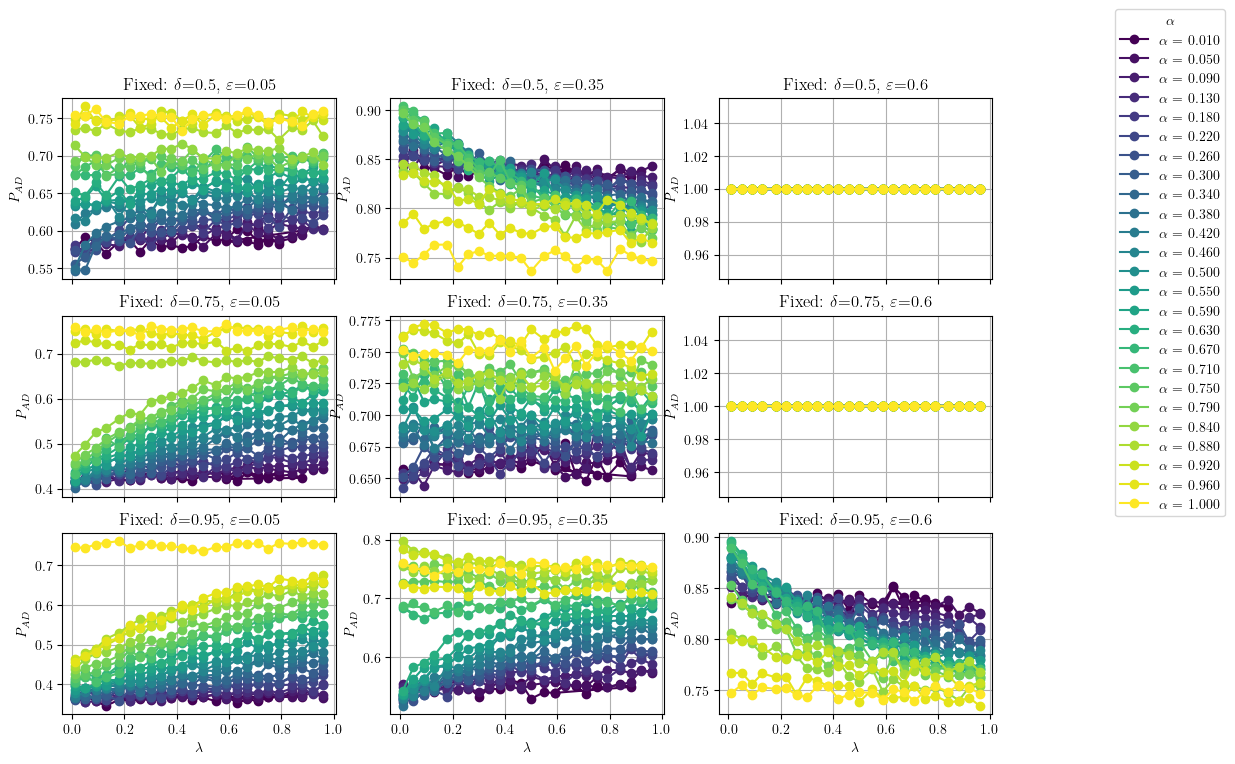

In [19]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.35},
    {'delta': 0.5, 'e': 0.6},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.35},
    {'delta': 0.75, 'e': 0.6},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.35},
    {'delta': 0.95, 'e': 0.6}
]

m=5000
y = 'P_AD'
plot_multiple_panels(df_fixed, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=5000, use_same_scale=True)
plot_multiple_panels(df_fixed, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=5000, use_same_scale=False)
plot_multiple_panels(df_fixed, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=5000, use_same_scale=True)
plot_multiple_panels(df_fixed, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=5000, use_same_scale=False)

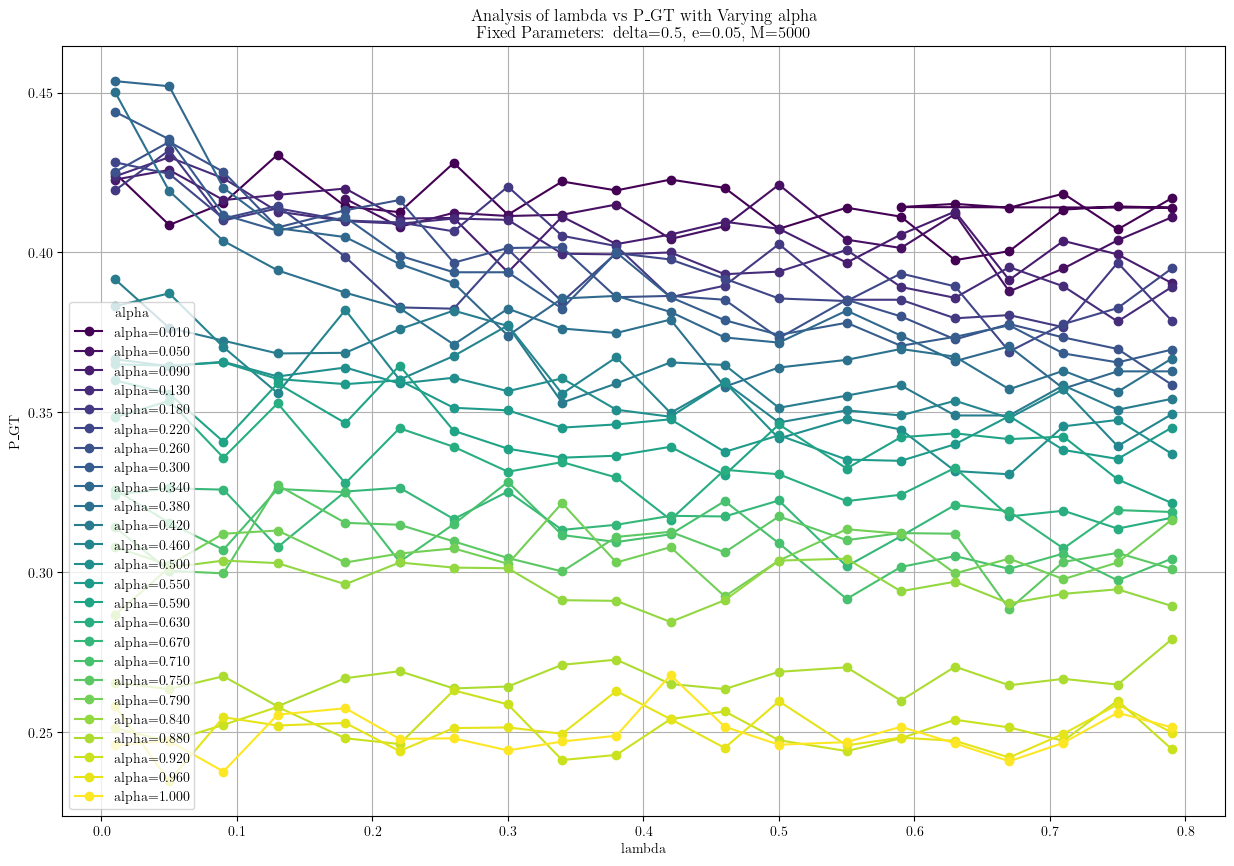

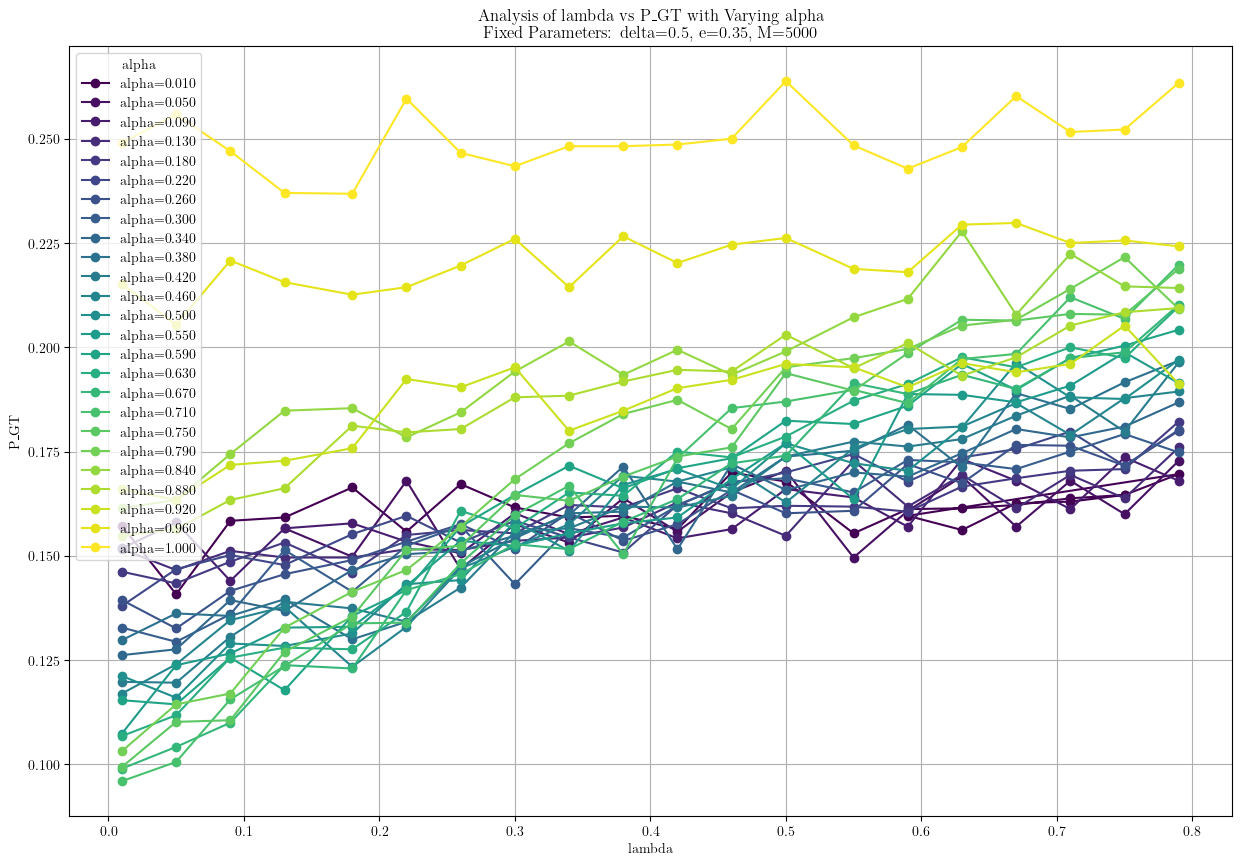

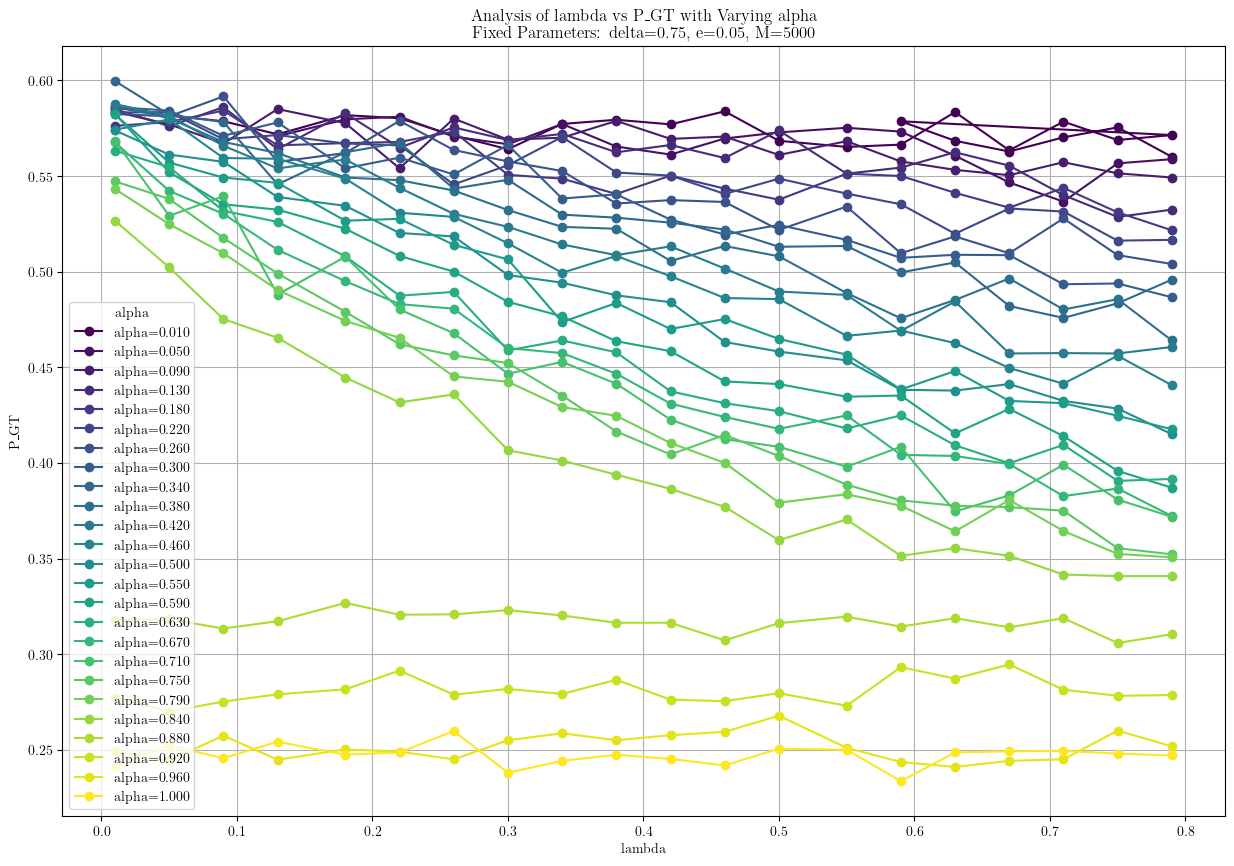

KeyboardInterrupt: 

In [19]:
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.5, 'e': 0.05, 'M': m}, 
    x_var='lambda', 
    varying_var='alpha'
)
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.5, 'e': 0.35, 'M': m}, 
    x_var='lambda', 
    varying_var='alpha'
)

plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.75, 'e': 0.05, 'M': m}, 
    x_var='lambda', 
    varying_var='alpha'
)
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.75, 'e': 0.35, 'M': m}, 
    x_var='lambda', 
    varying_var='alpha'
)

plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.95, 'e': 0.05, 'M': m}, 
    x_var='lambda', 
    varying_var='alpha'
)
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.95, 'e': 0.35, 'M': m}, 
    x_var='lambda', 
    varying_var='alpha'
)
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.95, 'e': 0.6, 'M': m}, 
    x_var='lambda', 
    varying_var='alpha'
)

<Axes: >

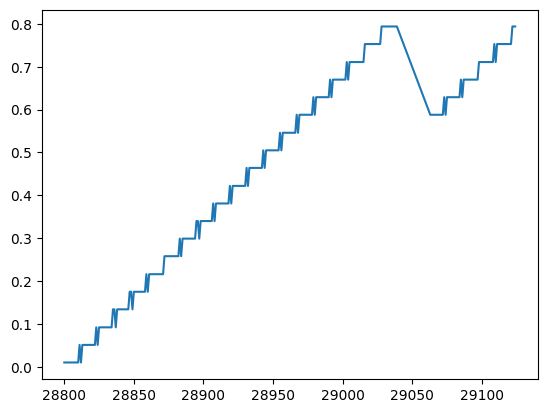

In [ ]:
df_fixed[(df_fixed['M'] == 5000)& (df_fixed['alpha'] == 0.01 )]['lambda'].plot()

## TIME ANALYSIS

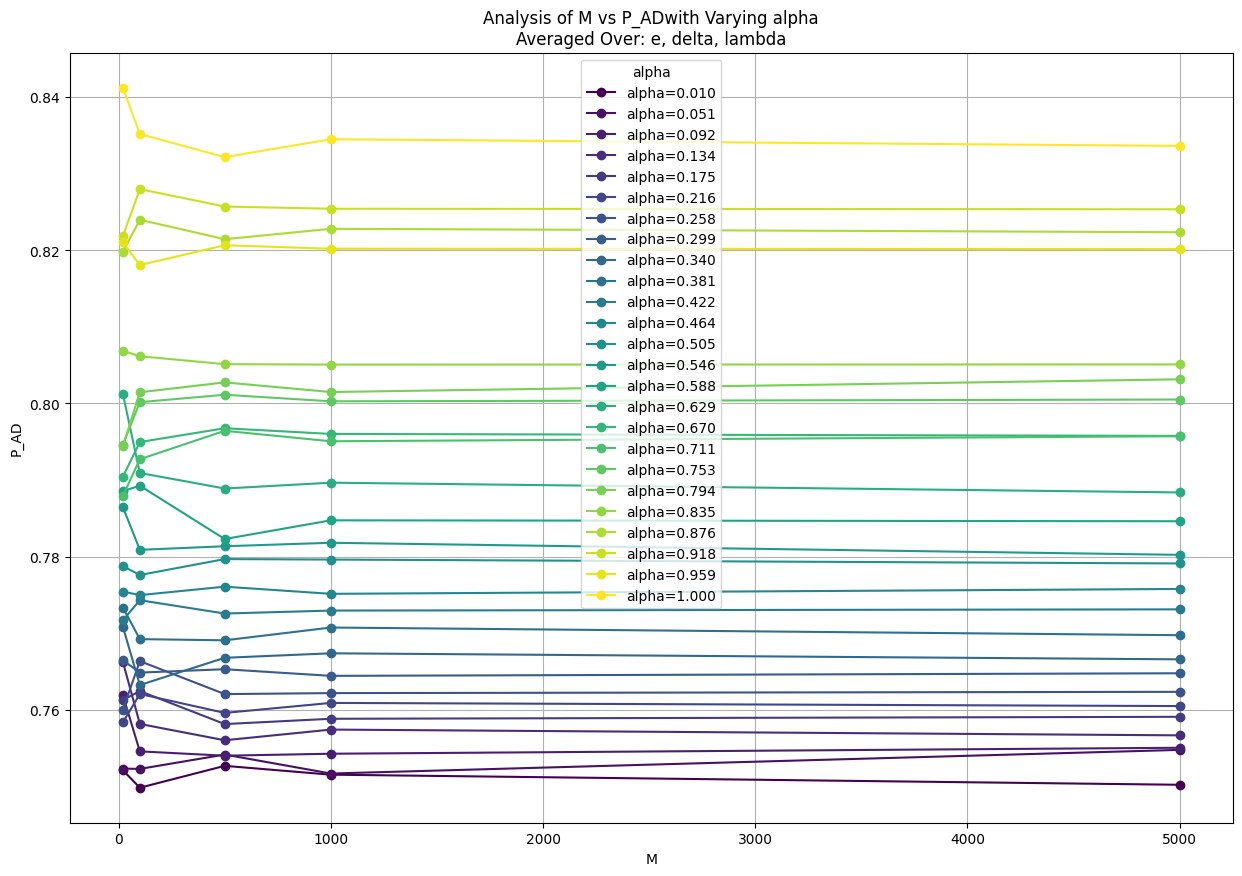

In [ ]:
plot_analysis_average_and_vary(
    df=df_fixed, 
    y_var='P_AD',
    averaging_vars=['e', 'delta', 'lambda'], 
    x_var='M', 
    varying_var='alpha'
)

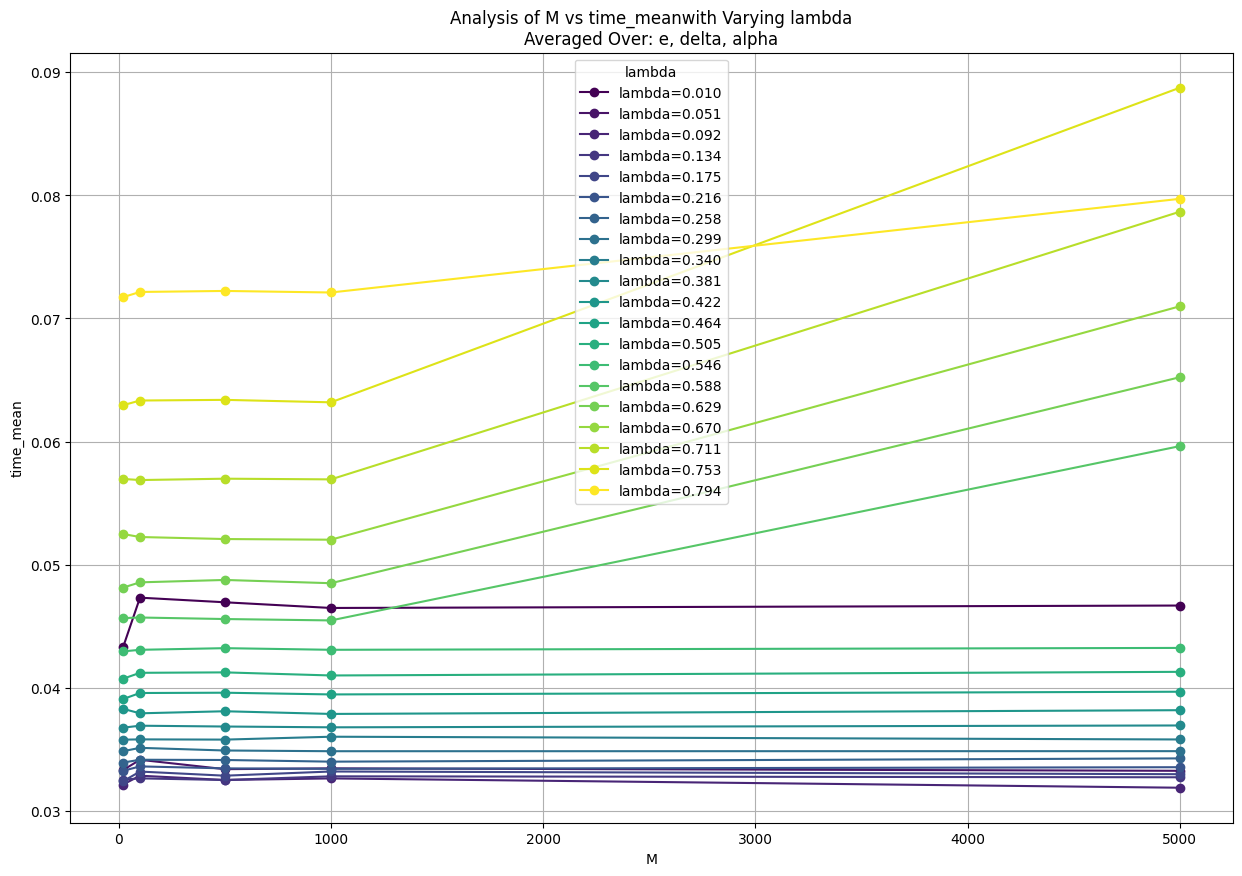

In [ ]:
plot_analysis_average_and_vary(
    df=df_fixed, 
    y_var='time_mean',
    averaging_vars=['e', 'delta', 'alpha'], 
    x_var='M', 
    varying_var='lambda'
)

In [ ]:
a = 0.010


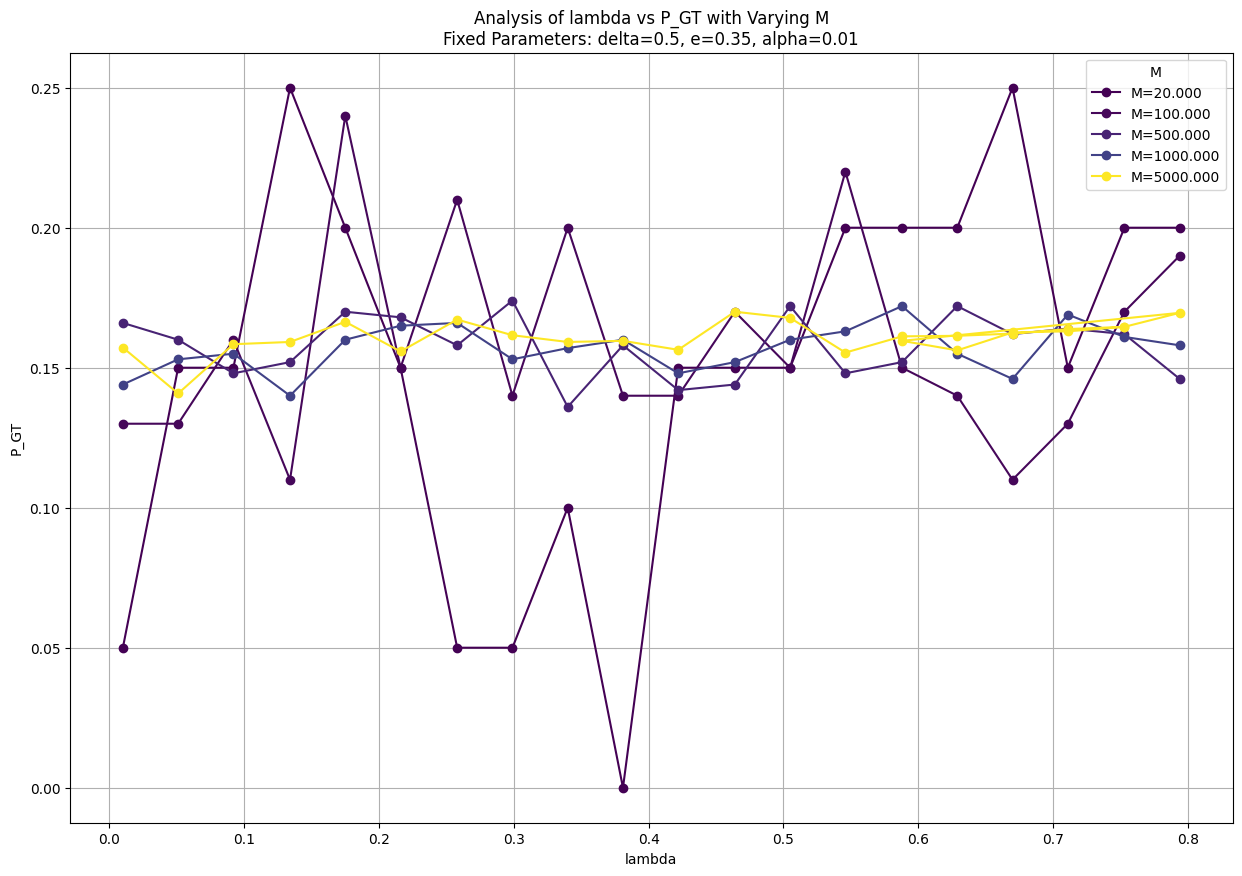

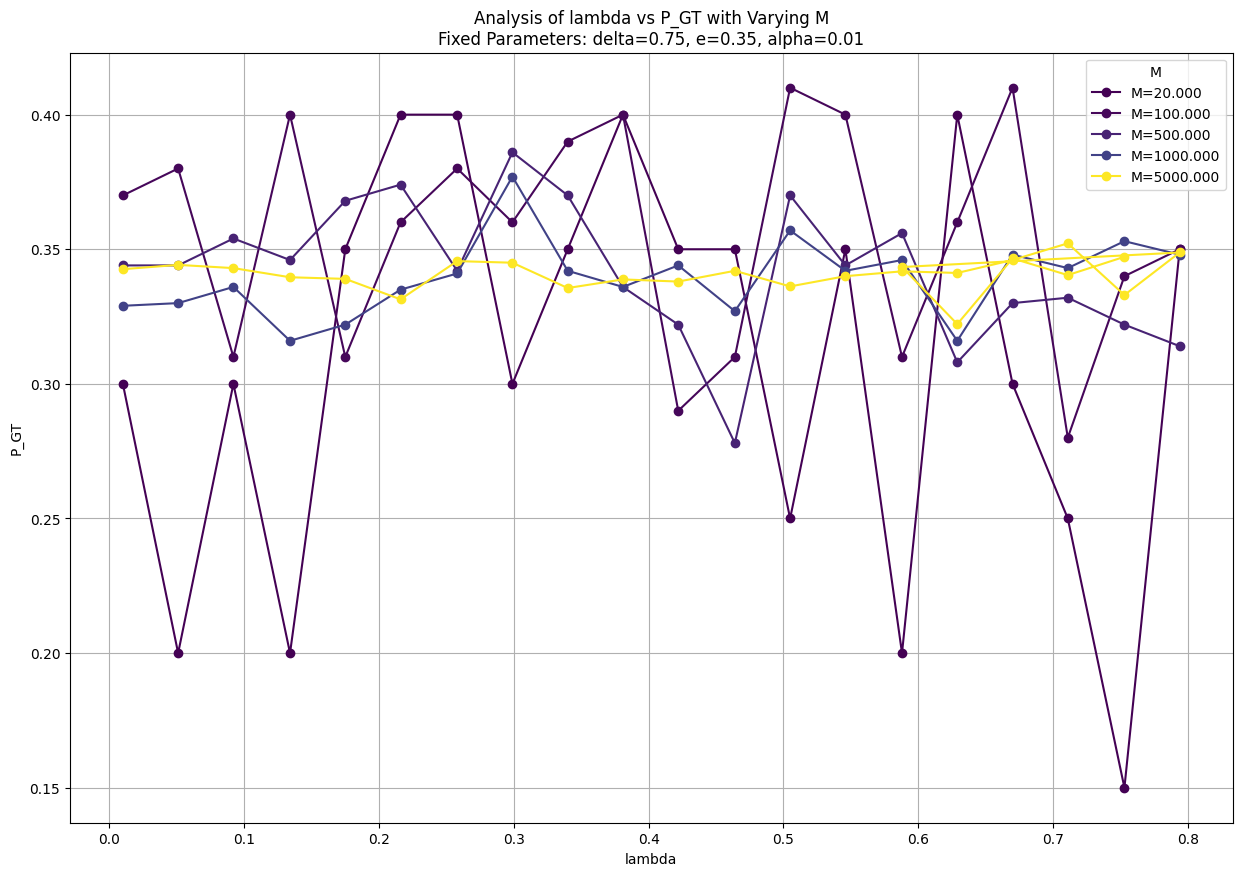

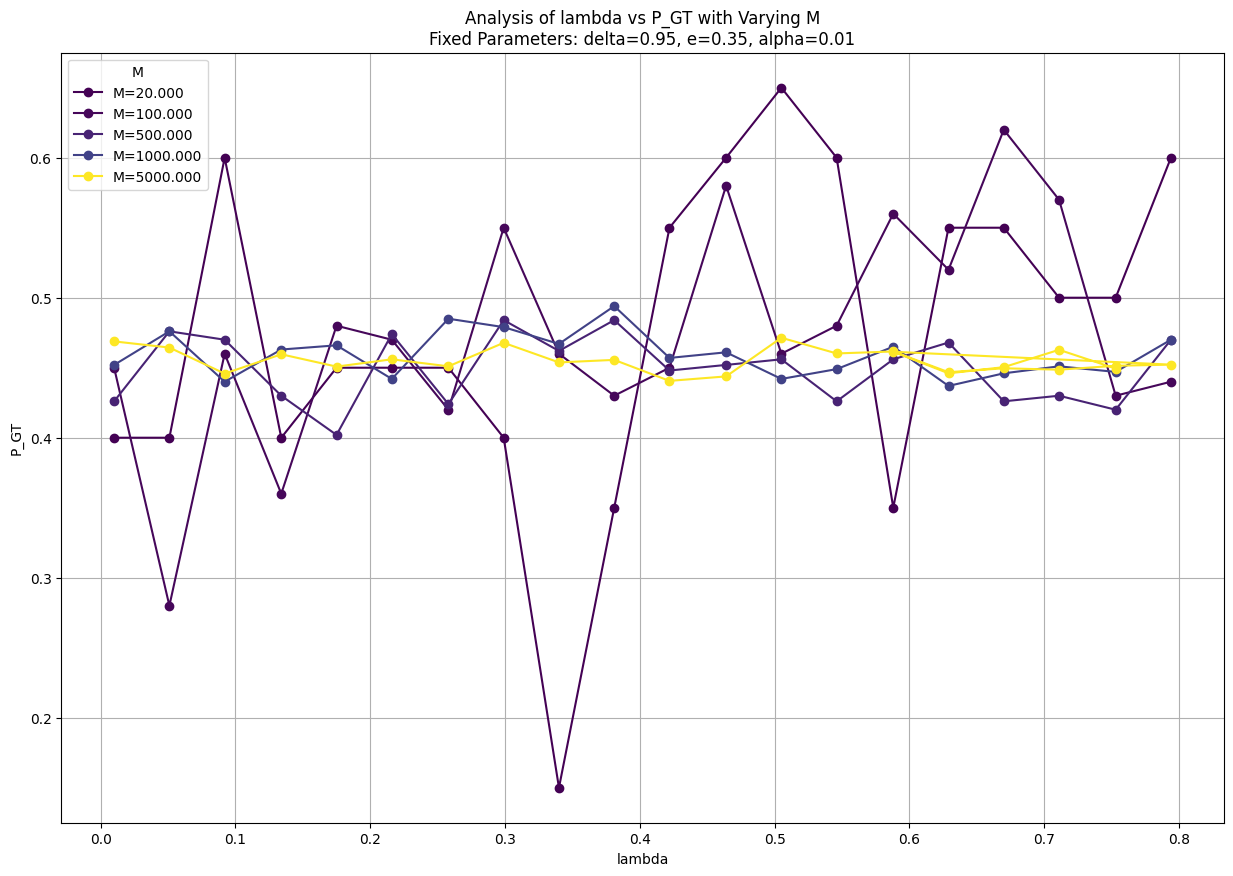

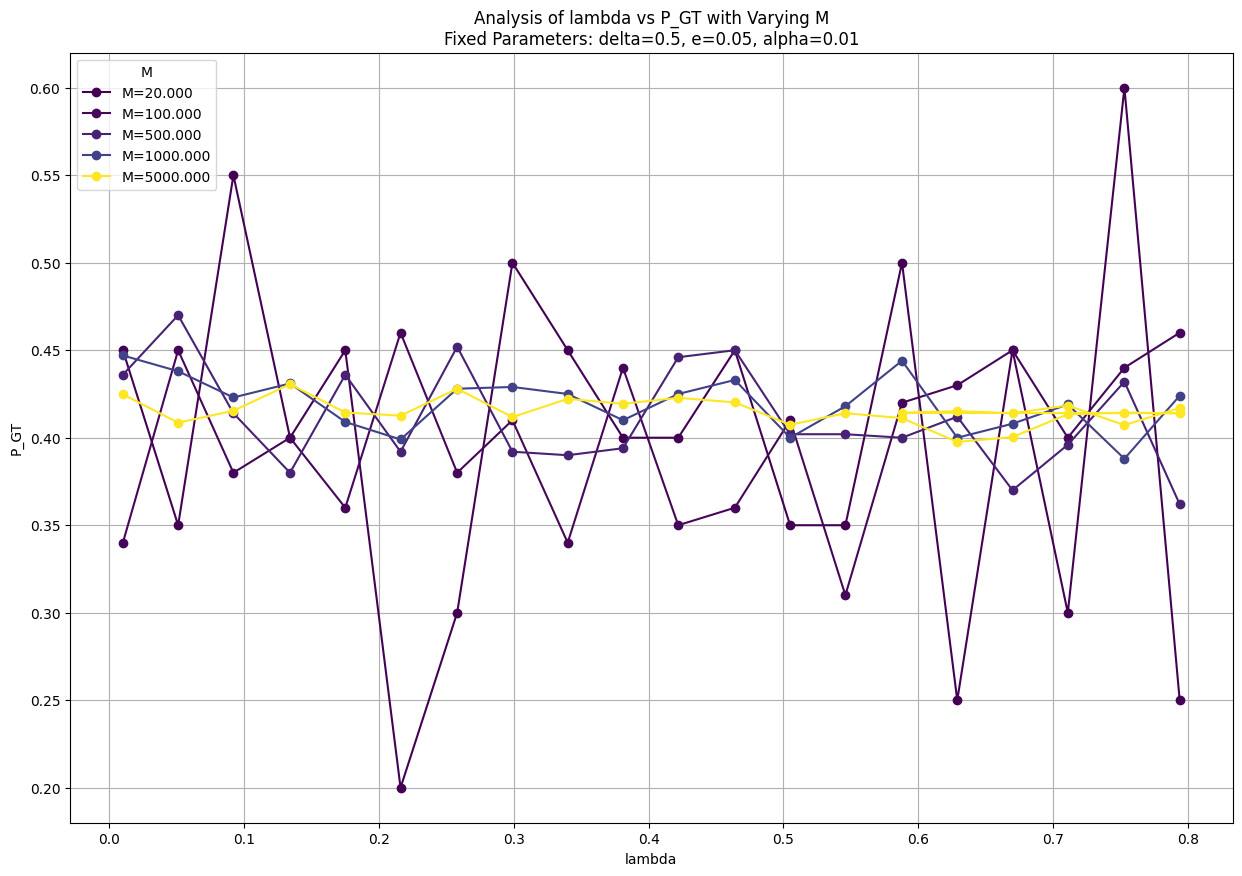

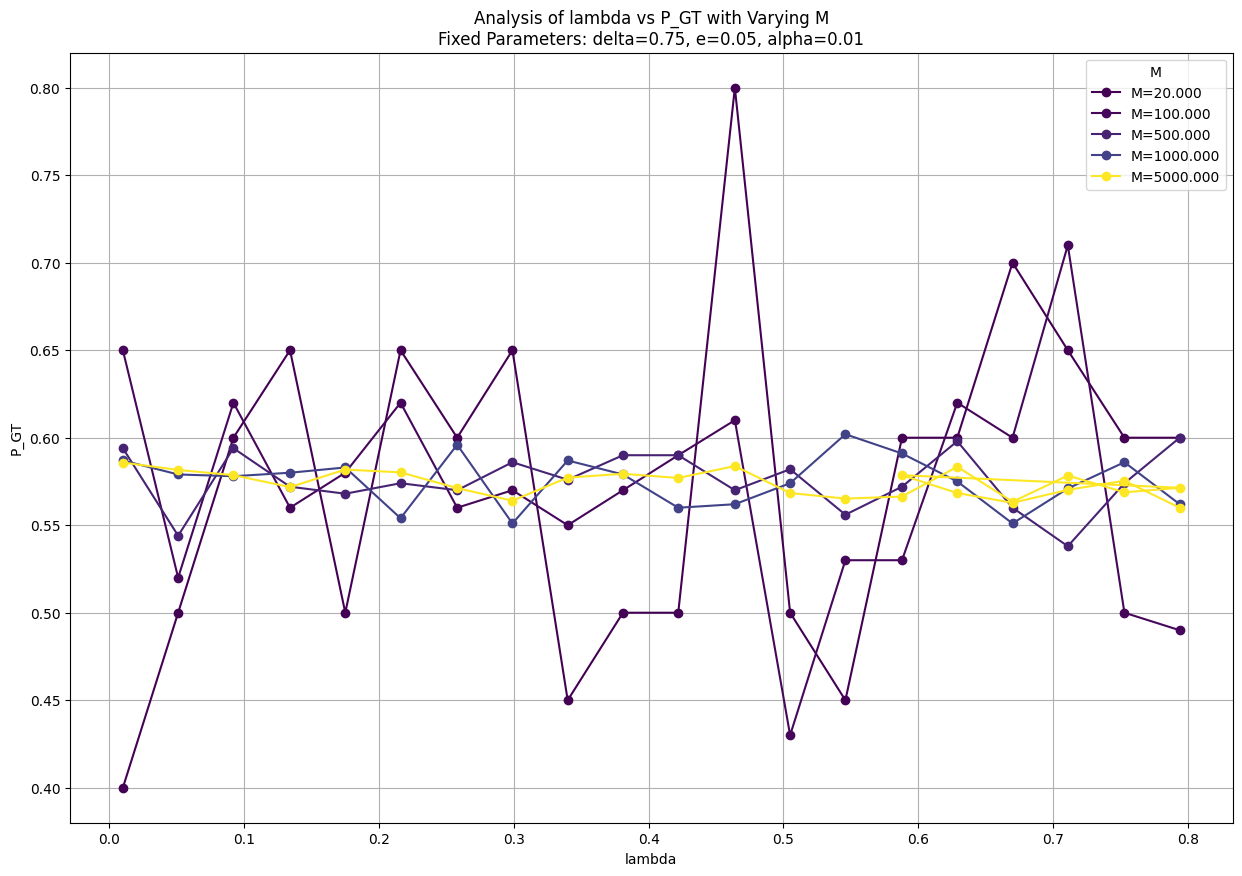

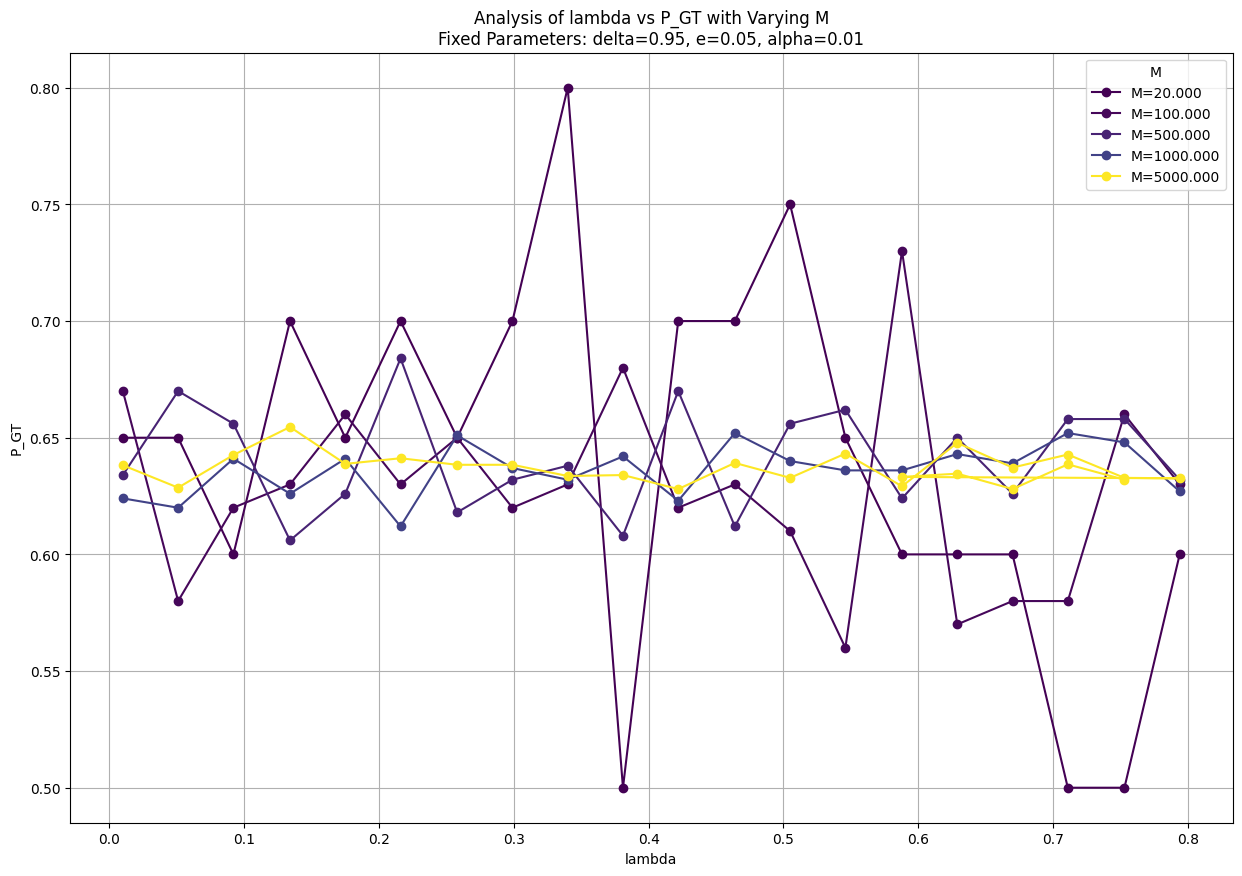

In [ ]:
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.5, 'e': 0.35, 'alpha': a}, 
    x_var='lambda', 
    varying_var='M'
)
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.75, 'e': 0.35, 'alpha': a}, 
    x_var='lambda', 
    varying_var='M'
)
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.95, 'e': 0.35, 'alpha': a}, 
    x_var='lambda', 
    varying_var='M'
)
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.5, 'e': 0.05, 'alpha': a}, 
    x_var='lambda', 
    varying_var='M'
)
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.75, 'e': 0.05, 'alpha': a}, 
    x_var='lambda', 
    varying_var='M'
)
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.95, 'e': 0.05, 'alpha': a}, 
    x_var='lambda', 
    varying_var='M'
)